# DS-04 — Delay Risk (Rebuild Final)

## Quy ước đã chốt

- **Primary holdout:** chia **ngẫu nhiên theo `project_id`**; không project nào xuất hiện đồng thời ở train/test.
- **GroupKFold(5)** trên tập train là phép đánh giá CV chính.
- Primary holdout này **không phải temporal holdout**.
- `as_of_date` chỉ dùng cho mô tả/audit, không dùng để chọn test projects.
- Right-censoring được kiểm tra **theo hai nhóm project train/test trên full population**, trước khi loại các dòng `censored`.
- Feature selection dùng **whitelist** theo `feature_dictionary_v5.md`.
- `assignee_id` là mã định danh, không phải feature.
- **CatBoost dùng categorical features gốc**, không qua one-hot preprocessor.
- Không tuning chỉ để làm metric đẹp.


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)

warnings.filterwarnings("ignore")

TRAIN_PATH = "delay_risk_train.csv"
TEST_PATH = "delay_risk_test.csv"
FULL_PATH = "delay_risk_discipline_level_full.csv"
RANDOM_STATE = 42
N_SPLITS = 5

print("Working directory:", os.getcwd())
print("Train exists:", os.path.exists(TRAIN_PATH))
print("Test exists :", os.path.exists(TEST_PATH))
print("Full exists :", os.path.exists(FULL_PATH))


Working directory: d:\Prj_TT_Hidecc\DS04
Train exists: True
Test exists : True
Full exists : True


In [2]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
full = pd.read_csv(FULL_PATH)

for df in (train, test, full):
    for c in ("as_of_date", "end_date", "actual_close_date"):
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")

print("Primary train:", train.shape)
print("Primary test :", test.shape)
print("Full audit   :", full.shape)
print("Train projects:", train["project_id"].nunique())
print("Test projects :", test["project_id"].nunique())


Primary train: (391, 17)
Primary test : (153, 17)
Full audit   : (620, 17)
Train projects: 42
Test projects : 17


## 1. Right-censoring audit

Primary train/test CSV đã loại các observation `censored`, vì vậy không thể chỉ nhìn vào hai CSV để đánh giá censoring bias.

Phép kiểm đúng là:

1. Lấy danh sách 42 project train và 17 project test từ primary split.
2. Quay lại **full population**.
3. Gán toàn bộ observation của các project đó vào hai nhóm.
4. So sánh:
   - tỷ lệ `censored`
   - số dòng bị censored
   - tỷ lệ label 1 trên phần trainable.

Mục tiêu là kiểm tra liệu test-group có bị cắt mất một phần lớn observation do right-censoring hay không.


In [3]:
# Censoring audit trên FULL population, phân theo nhóm project của primary split.

train_projects = set(train["project_id"].dropna())
test_projects = set(test["project_id"].dropna())

full_train_group = full[full["project_id"].isin(train_projects)].copy()
full_test_group = full[full["project_id"].isin(test_projects)].copy()

def summarize_group(name, group_df):
    cens_mask = group_df["censor_status"].eq("censored")
    trainable_group = group_df[group_df["label"].notna()].copy()

    return {
        "group": name,
        "projects": group_df["project_id"].nunique(),
        "full_rows": len(group_df),
        "censored_rows": int(cens_mask.sum()),
        "censored_rate": cens_mask.mean(),
        "trainable_rows": len(trainable_group),
        "positive_rate": (
            trainable_group["label"].astype(int).mean()
            if len(trainable_group) else np.nan
        ),
    }

censoring_split_audit = pd.DataFrame([
    summarize_group("Train projects", full_train_group),
    summarize_group("Test projects", full_test_group),
])

display(censoring_split_audit)

train_cens = censoring_split_audit.loc[
    censoring_split_audit["group"] == "Train projects", "censored_rate"
].iloc[0]
test_cens = censoring_split_audit.loc[
    censoring_split_audit["group"] == "Test projects", "censored_rate"
].iloc[0]

print(
    f"Tỷ lệ censored: train-group = {train_cens:.1%} | "
    f"test-group = {test_cens:.1%}"
)
print(
    f"Test-group bị censored khoảng {test_cens:.1%} "
    f"≈ {test_cens * 10:.1f}/10 quan sát."
)

print(
    "\nDiễn giải: nếu test-group có tỷ lệ censored cao hơn rất nhiều so với "
    "train-group, test đang chịu selection/censoring bias đáng kể. "
    "Không suy diễn rằng censoring là nguyên nhân duy nhất của AUC thấp."
)


,group,projects,full_rows,censored_rows,censored_rate,trainable_rows,positive_rate
0,Train projects,42,442,51,0.115385,391,0.511509
1,Test projects,17,178,25,0.140449,153,0.496732


Tỷ lệ censored: train-group = 11.5% | test-group = 14.0%
Test-group bị censored khoảng 14.0% ≈ 1.4/10 quan sát.

Diễn giải: nếu test-group có tỷ lệ censored cao hơn rất nhiều so với train-group, test đang chịu selection/censoring bias đáng kể. Không suy diễn rằng censoring là nguyên nhân duy nhất của AUC thấp.


## 2. Chia holdout chính theo nhóm project ngẫu nhiên

Primary holdout được tạo ở **project level**:

1. Lấy toàn bộ `project_id` từ full population.
2. Chia ngẫu nhiên 70/30 project với `RANDOM_STATE = 42`.
3. Giữ toàn bộ discipline của một project ở cùng một phía.
4. Sau khi gán project vào train/test mới loại true `censored` khỏi population dùng train model.

Như vậy:

- không có project overlap;
- test không còn bị chọn theo thứ tự thời gian;
- phép kiểm censoring ở Section 1 sử dụng đúng hai nhóm project của primary holdout.

`as_of_date` không được dùng để chọn test và không gọi đây là temporal holdout.


In [4]:
train_projects = set(train["project_id"].dropna())
test_projects = set(test["project_id"].dropna())
overlap = train_projects & test_projects

print("== PRIMARY RANDOM GROUP HOLDOUT ==")
print(f"Train: {len(train)} rows / {len(train_projects)} projects")
print(f"Test : {len(test)} rows / {len(test_projects)} projects")
print("Project overlap:", len(overlap))

if overlap:
    raise AssertionError(f"Project leakage detected: {sorted(overlap)[:10]}")

print("[Leakage check] No project overlap: OK")

print("\n== Temporal information (descriptive only) ==")
print("Train as_of:", train["as_of_date"].min(), "→", train["as_of_date"].max())
print("Test  as_of:", test["as_of_date"].min(), "→", test["as_of_date"].max())
print("Note: these ranges are descriptive; they are NOT a temporal holdout.")


== PRIMARY RANDOM GROUP HOLDOUT ==
Train: 391 rows / 42 projects
Test : 153 rows / 17 projects
Project overlap: 0
[Leakage check] No project overlap: OK

== Temporal information (descriptive only) ==
Train as_of: 2025-10-30 00:00:00 → 2026-08-08 00:00:00
Test  as_of: 2025-11-25 00:00:00 → 2026-08-08 00:00:00
Note: these ranges are descriptive; they are NOT a temporal holdout.


In [5]:
TARGET = next((c for c in ["label", "delay_label", "is_late"] if c in train.columns), None)
if TARGET is None:
    raise KeyError("Target column not found. Expected label/delay_label/is_late.")

# WHITELIST theo feature_dictionary_v5.md.
# Không dùng blacklist để tránh identifier mới tự động lọt vào model.
numeric_feature_whitelist = [
    "contract_value",
    "planned_duration_days",
    "n_disciplines_known_at_snapshot",
    "n_open_disciplines_at_snapshot",
    "total_workload_pct",
    "pct_staff_overloaded_at_snapshot",
    "n_open_overdue_tasks_at_snapshot",
    "pm_historic_late_rate",
    "customer_historic_late_rate",
]

categorical_feature_whitelist = [
    "project_type",
    "discipline",
]

feature_whitelist = numeric_feature_whitelist + categorical_feature_whitelist

missing_train = [c for c in feature_whitelist if c not in train.columns]
missing_test = [c for c in feature_whitelist if c not in test.columns]

if missing_train or missing_test:
    raise KeyError(
        f"Thiếu feature theo dictionary. train={missing_train}, test={missing_test}"
    )

# Không cho identifier lọt vào feature dictionary.
for forbidden in ["assignee_id", "project_id"]:
    assert forbidden not in feature_whitelist, f"Identifier lọt vào feature: {forbidden}"

features = feature_whitelist

constant = [
    c for c in features
    if train[c].nunique(dropna=True) <= 1
]
if constant:
    print("Cảnh báo: feature constant trong train:", constant)

X_train = train[features].copy()
X_test = test[features].copy()
y_train = train[TARGET].astype(int)
y_test = test[TARGET].astype(int)

print("Target:", TARGET)
print("Final feature whitelist:", features)
print("Numeric features:", numeric_feature_whitelist)
print("Categorical features:", categorical_feature_whitelist)

audit = pd.DataFrame({
    "feature": features,
    "dtype": [str(train[c].dtype) for c in features],
    "train_missing_pct": [train[c].isna().mean() for c in features],
    "test_missing_pct": [test[c].isna().mean() for c in features],
    "train_nunique": [train[c].nunique(dropna=True) for c in features],
})
display(audit)


Target: label
Final feature whitelist: ['contract_value', 'planned_duration_days', 'n_disciplines_known_at_snapshot', 'n_open_disciplines_at_snapshot', 'total_workload_pct', 'pct_staff_overloaded_at_snapshot', 'n_open_overdue_tasks_at_snapshot', 'pm_historic_late_rate', 'customer_historic_late_rate', 'project_type', 'discipline']
Numeric features: ['contract_value', 'planned_duration_days', 'n_disciplines_known_at_snapshot', 'n_open_disciplines_at_snapshot', 'total_workload_pct', 'pct_staff_overloaded_at_snapshot', 'n_open_overdue_tasks_at_snapshot', 'pm_historic_late_rate', 'customer_historic_late_rate']
Categorical features: ['project_type', 'discipline']


,feature,dtype,train_missing_pct,test_missing_pct,train_nunique
0,contract_value,float64,0.0,0.0,8
1,planned_duration_days,int64,0.0,0.0,30
2,n_disciplines_known_at_snapshot,int64,0.0,0.0,11
3,n_open_disciplines_at_snapshot,int64,0.0,0.0,7
4,total_workload_pct,float64,0.0,0.0,44
5,pct_staff_overloaded_at_snapshot,float64,0.0,0.0,48
6,n_open_overdue_tasks_at_snapshot,int64,0.0,0.0,5
7,pm_historic_late_rate,float64,0.0,0.0,347
8,customer_historic_late_rate,float64,0.0,0.0,321
9,project_type,object,0.0,0.0,4


In [6]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in features if c not in numeric_features]

# Bộ tiền xử lý chỉ được sử dụng bởi Logistic Regression và Random Forest.
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features),
])

# CatBoost nhận các cột phân loại ORIGINAL.
# Không one-hot encode các cột này trước CatBoost.
X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for col in categorical_features:
    X_train_cb[col] = X_train_cb[col].fillna("__MISSING__").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("__MISSING__").astype(str)

catboost_cat_indices = [X_train_cb.columns.get_loc(c) for c in categorical_features]

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

try:
    from catboost import CatBoostClassifier
except ImportError:
    raise ImportError(
        "CatBoost is required for the DS-04 3-baseline run. "
        "Install catboost before running this notebook."
    )

# Chỉ dùng làm dấu hiệu nhận biết. evaluate_primary() tạo ra một bộ ước lượng CatBoost gốc mới
# cho mỗi lần chia dữ liệu (fold) và cho quá trình huấn luyện cuối cùng.
models["CatBoost"] = None

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("CatBoost categorical columns:", categorical_features)
print("Baselines:", list(models.keys()))


Numeric features: ['contract_value', 'planned_duration_days', 'n_disciplines_known_at_snapshot', 'n_open_disciplines_at_snapshot', 'total_workload_pct', 'pct_staff_overloaded_at_snapshot', 'n_open_overdue_tasks_at_snapshot', 'pm_historic_late_rate', 'customer_historic_late_rate']
Categorical features: ['project_type', 'discipline']
CatBoost categorical columns: ['project_type', 'discipline']
Baselines: ['Logistic Regression', 'Random Forest', 'CatBoost']


In [7]:
def make_catboost():
    """Create a fresh CatBoost estimator for each fold/final fit."""
    return CatBoostClassifier(
        iterations=300,
        depth=5,
        learning_rate=0.05,
        loss_function="Logloss",
        verbose=False,
        random_seed=RANDOM_STATE,
        cat_features=catboost_cat_indices,
    )


def evaluate_primary(name, estimator):
    """GroupKFold(5) + untouched random project-group test holdout."""
    groups = train["project_id"].reset_index(drop=True)
    Xtr = X_train.reset_index(drop=True)
    ytr = y_train.reset_index(drop=True)
    Xtr_cb = X_train_cb.reset_index(drop=True)

    cv = GroupKFold(n_splits=N_SPLITS)
    fold_auc = []

    for fold, (tr_idx, va_idx) in enumerate(
        cv.split(Xtr, ytr, groups=groups), start=1
    ):
        y_tr = ytr.iloc[tr_idx]
        y_va = ytr.iloc[va_idx]

        if name == "CatBoost":
            model_fold = make_catboost()
            model_fold.fit(Xtr_cb.iloc[tr_idx], y_tr)
            p_va = model_fold.predict_proba(Xtr_cb.iloc[va_idx])[:, 1]
        else:
            pipe_fold = Pipeline([
                ("prep", clone(preprocessor)),
                ("model", clone(estimator)),
            ])
            pipe_fold.fit(Xtr.iloc[tr_idx], y_tr)
            p_va = pipe_fold.predict_proba(Xtr.iloc[va_idx])[:, 1]

        if y_va.nunique() == 2:
            fold_auc.append(roc_auc_score(y_va, p_va))

    if name == "CatBoost":
        fitted = make_catboost()
        fitted.fit(X_train_cb, y_train)
        prob = fitted.predict_proba(X_test_cb)[:, 1]
    else:
        fitted = Pipeline([
            ("prep", clone(preprocessor)),
            ("model", clone(estimator)),
        ])
        fitted.fit(X_train, y_train)
        prob = fitted.predict_proba(X_test)[:, 1]

    pred = (prob >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])

    result = {
        "model": name,
        "test_roc_auc": roc_auc_score(y_test, prob),
        "cv_auc_mean": np.mean(fold_auc),
        "cv_auc_std": np.std(fold_auc, ddof=1) if len(fold_auc) > 1 else np.nan,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "confusion_matrix": cm.tolist(),
    }

    print("\n" + name)
    print(
        "CV ROC-AUC:", np.round(fold_auc, 3),
        f"| mean={result['cv_auc_mean']:.3f} "
        f"| std={result['cv_auc_std']:.3f}"
    )
    print(
        f"Test: Precision={result['precision']:.3f} "
        f"Recall={result['recall']:.3f} "
        f"F1={result['f1']:.3f} "
        f"ROC-AUC={result['test_roc_auc']:.3f}"
    )
    print("Confusion Matrix:\n", cm)

    return result, fitted, prob, pred


evaluation = {}
for name, estimator in models.items():
    result, fitted, prob, pred = evaluate_primary(name, estimator)
    evaluation[name] = {
        "result": result,
        "fitted": fitted,
        "prob": prob,
        "pred": pred,
    }

primary_results = pd.DataFrame(
    [evaluation[name]["result"] for name in models]
)

fitted_pipes = {name: evaluation[name]["fitted"] for name in models}
test_probabilities = {name: evaluation[name]["prob"] for name in models}
test_predictions = {name: evaluation[name]["pred"] for name in models}

display(primary_results)



Logistic Regression
CV ROC-AUC: [0.577 0.635 0.638 0.549 0.704] | mean=0.621 | std=0.060
Test: Precision=0.581 Recall=0.566 F1=0.573 ROC-AUC=0.614
Confusion Matrix:
 [[46 31]
 [33 43]]

Random Forest
CV ROC-AUC: [0.6   0.615 0.689 0.611 0.717] | mean=0.646 | std=0.053
Test: Precision=0.613 Recall=0.605 F1=0.609 ROC-AUC=0.640
Confusion Matrix:
 [[48 29]
 [30 46]]

CatBoost
CV ROC-AUC: [0.549 0.603 0.684 0.607 0.57 ] | mean=0.603 | std=0.051
Test: Precision=0.606 Recall=0.526 F1=0.563 ROC-AUC=0.614
Confusion Matrix:
 [[51 26]
 [36 40]]


,model,test_roc_auc,cv_auc_mean,cv_auc_std,precision,recall,f1,confusion_matrix
0,Logistic Regression,0.614149,0.620534,0.060266,0.581081,0.565789,0.573333,"[[46, 31], [33, 43]]"
1,Random Forest,0.639610,0.646378,0.052869,0.613333,0.605263,0.609272,"[[48, 29], [30, 46]]"
2,CatBoost,0.613636,0.602676,0.051370,0.606061,0.526316,0.563380,"[[51, 26], [36, 40]]"


## Visualization — ROC Curve

ROC Curve được vẽ cho cả ba baseline trên tập test để trực quan hóa khả năng phân biệt hai lớp ở các threshold khác nhau.


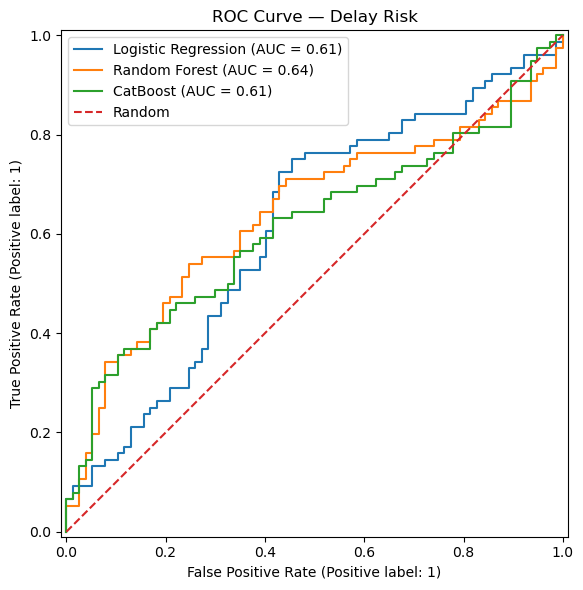

In [8]:
# ROC 
fig, ax = plt.subplots(figsize=(7, 6))

for name, y_score in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test,
        y_score,
        name=name,
        ax=ax,
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random")
ax.set_title("ROC Curve — Delay Risk")
ax.legend()
plt.tight_layout()
plt.show()


## Visualization — Confusion Matrix

Confusion Matrix được vẽ cho cả ba baseline tại threshold mặc định `0.5`.


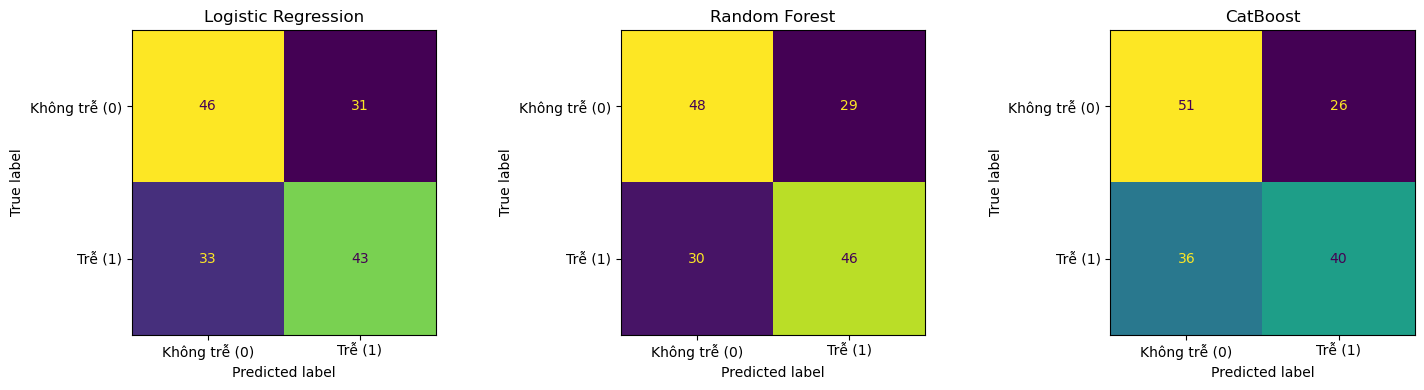

In [9]:
# Confusion matrices
fig, axes = plt.subplots(
    1,
    len(test_predictions),
    figsize=(5 * len(test_predictions), 4),
)

if len(test_predictions) == 1:
    axes = [axes]

for ax, (name, y_pred) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Không trễ (0)", "Trễ (1)"],
        ax=ax,
        colorbar=False,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


## 4. Right-censoring — kết luận

Không sử dụng strict-follow-up buffer 0/30/60 làm phép kiểm chính.

Phép kiểm chính là bảng so sánh **hai nhóm project train/test trên full population**, trước khi censored rows bị loại:

- nhóm train: các project được đưa vào primary random holdout train;
- nhóm test: các project được đưa vào primary random holdout test;
- `censored` được đo trên toàn bộ observation của các project đó.

Mục tiêu là kiểm tra liệu test có bị selection/censoring bias mạnh hơn train hay không.

Không suy diễn rằng censoring là nguyên nhân duy nhất khiến AUC thấp.


In [10]:
# Bản tóm tắt sẵn sàng báo cáo về kiểm toán kiểm duyệt dữ liệu train/test
summary = censoring_split_audit.copy()

summary["censored_rate"] = summary["censored_rate"].map(lambda x: f"{x:.1%}")
summary["positive_rate"] = summary["positive_rate"].map(
    lambda x: f"{x:.1%}" if pd.notna(x) else "NA"
)

display(summary)

print(
    "Điểm cần nhấn mạnh: phép kiểm censoring được thực hiện trên FULL population "
    "theo project group, trước khi các dòng censored bị loại khỏi primary train/test."
)


,group,projects,full_rows,censored_rows,censored_rate,trainable_rows,positive_rate
0,Train projects,42,442,51,11.5%,391,51.2%
1,Test projects,17,178,25,14.0%,153,49.7%


Điểm cần nhấn mạnh: phép kiểm censoring được thực hiện trên FULL population theo project group, trước khi các dòng censored bị loại khỏi primary train/test.


## 5. Kết luận

### Tập chính

- Primary split được thực hiện theo `project_id` để kiểm soát leakage giữa các discipline của cùng project.
- `as_of_date` chỉ là temporal diagnostic, không phải temporal holdout hoàn chỉnh.
- Feature được chọn bằng whitelist theo `feature_dictionary_v5.md`.

### Right-censoring

- True `censored` được loại khỏi population dùng train/test.
- Phép kiểm chính là so sánh tỷ lệ censored giữa **train-group và test-group trên full population**.
- Nếu test-group bị censored cao hơn rõ rệt, đó là một giới hạn quan trọng của phép đánh giá.

### Feature

- `assignee_id` là identifier nên không được dùng làm feature.
- `discipline` được giữ vì là biến nghiệp vụ có ý nghĩa.
- Không dùng các biến outcome-derived như `actual_close_date` hoặc `censor_status`.

### Mô hình hóa

- Ba baseline: Logistic Regression, Random Forest, CatBoost.
- GroupKFold(5) theo `project_id`.
- Không tuning chỉ nhằm đẩy AUC lên cao.
- Kết quả thấp hoặc gần random được giữ nguyên như một baseline trung thực.
